# ESE5023 Assignment 04
Huang Xiaoqi  12632722

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

DATA = Path(".")

## 1. Global Earthquakes

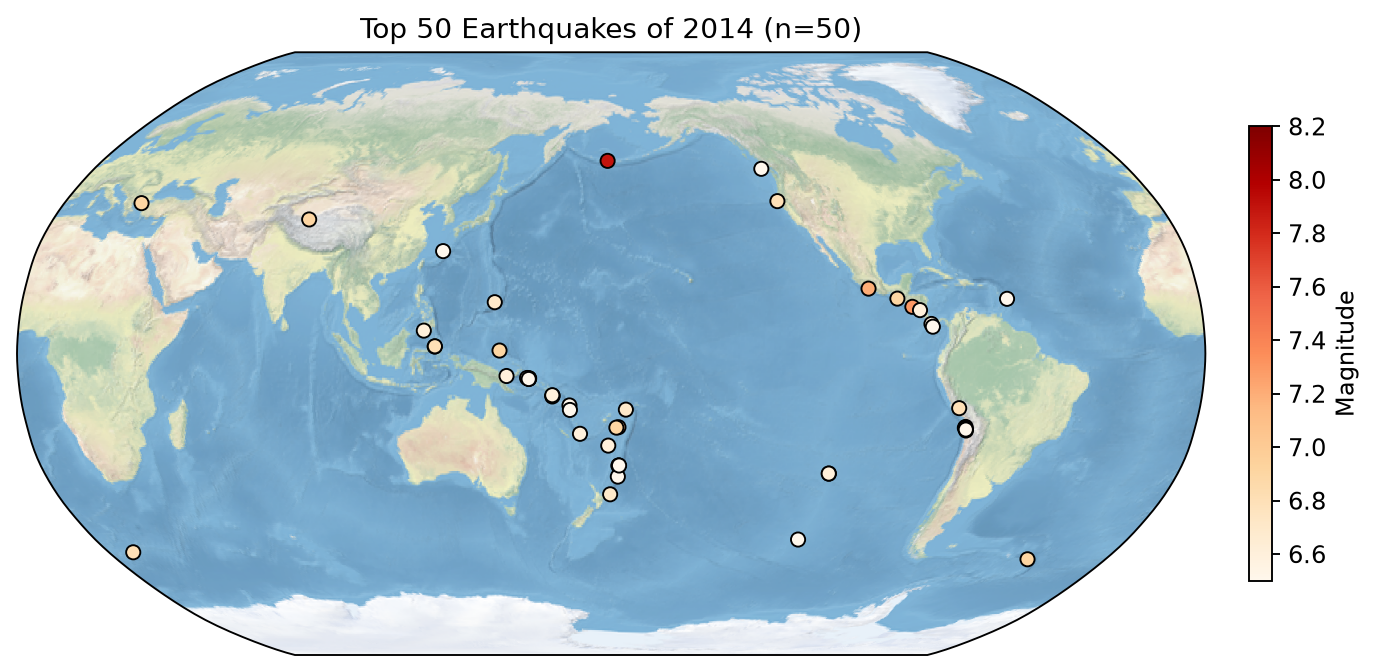

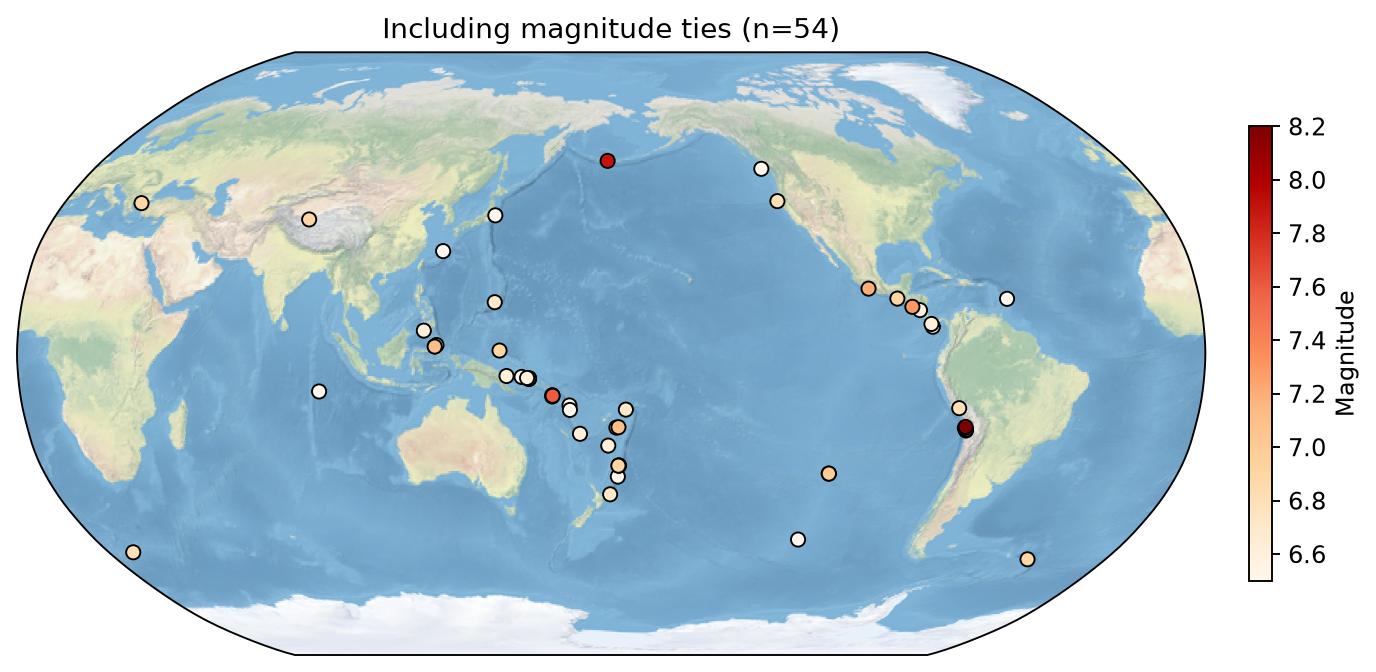

In [2]:
# 分别选取前50次地震，以及包含并列第50名的全部地震
earthquakes = pd.read_csv(DATA / "usgs_earthquakes.csv")
top50 = earthquakes.nlargest(50, "mag")
with_ties = earthquakes[earthquakes.mag >= top50.mag.min()]

# 用相同投影和色标绘制两种选取结果
for quakes, title in [(top50, "Top 50 Earthquakes of 2014 (n=50)"),
                      (with_ties, "Including magnitude ties (n=54)")]:
    fig = plt.figure(figsize=(11, 5.6))
    ax = fig.add_subplot(projection=ccrs.Robinson(central_longitude=180))
    ax.stock_img()
    points = ax.scatter(quakes.longitude, quakes.latitude, c=quakes.mag, s=36,
                        cmap="OrRd", vmin=top50.mag.min(), vmax=top50.mag.max(),
                        edgecolors="black", linewidths=0.8,
                        transform=ccrs.PlateCarree(), zorder=3)
    ax.set_title(title)
    fig.colorbar(points, ax=ax, shrink=0.62, pad=0.03, label="Magnitude")
    plt.show()

## 2. Explore a NetCDF dataset

In [3]:
import json
from cartopy.io import shapereader
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
from cartopy.util import add_cyclic_point

# 读取小时平均风场并计算风速
wind = xr.open_dataset(DATA / "MERRA2_10m_wind_20260701_1230.nc", engine="scipy").isel(time=0)
u, v = wind.U10M, wind.V10M
speed = np.hypot(u, v)
vmax = float(np.ceil(speed.max()))
coast = list(shapereader.Reader(DATA / "map_data/ne_110m_coastline.shp").geometries())
borders = list(shapereader.Reader(DATA / "map_data/ne_110m_admin_0_boundary_lines_land.shp").geometries())
states = list(shapereader.Reader(DATA / "map_data/ne_110m_admin_1_states_provinces_lines.shp").geometries())
divides = json.loads((DATA / "map_data/continent_divides.geojson").read_text(encoding="utf-8"))

# 添加地图坐标、地理边界和风速色标
def finish_map(fig, ax, image, arrows, title):
    ax.add_geometries(coast, ccrs.PlateCarree(), facecolor="none", edgecolor="black", linewidth=0.55)
    grid = ax.gridlines(draw_labels=True, x_inline=False, y_inline=False,
                        linewidth=0.45, color="gray", alpha=0.7, linestyle="--")
    grid.top_labels = grid.right_labels = False
    grid.xlabel_style = grid.ylabel_style = {"size": 9}
    ax.set_title(title, fontsize=12)
    ax.quiverkey(arrows, 0.88, -0.10, 10, "10 m/s", labelpos="E", coordinates="axes")
    ax.text(0.50, -0.08, "Longitude", transform=ax.transAxes, ha="center", fontsize=9)
    fig.text(0.025, 0.56, "Latitude", va="center", rotation=90, fontsize=9)
    fig.colorbar(image, cax=fig.add_axes([0.18, 0.12, 0.64, 0.025]), orientation="horizontal",
                 label="10 m wind speed (m/s)")
    ax.text(0.02, 0.03, "MERRA-2\n0.5° × 0.625°\nHourly mean: 12:00–13:00 UTC",
            transform=ax.transAxes, fontsize=8, bbox=dict(facecolor="white", alpha=0.9, edgecolor="gray"))
    plt.show()

### 2.1

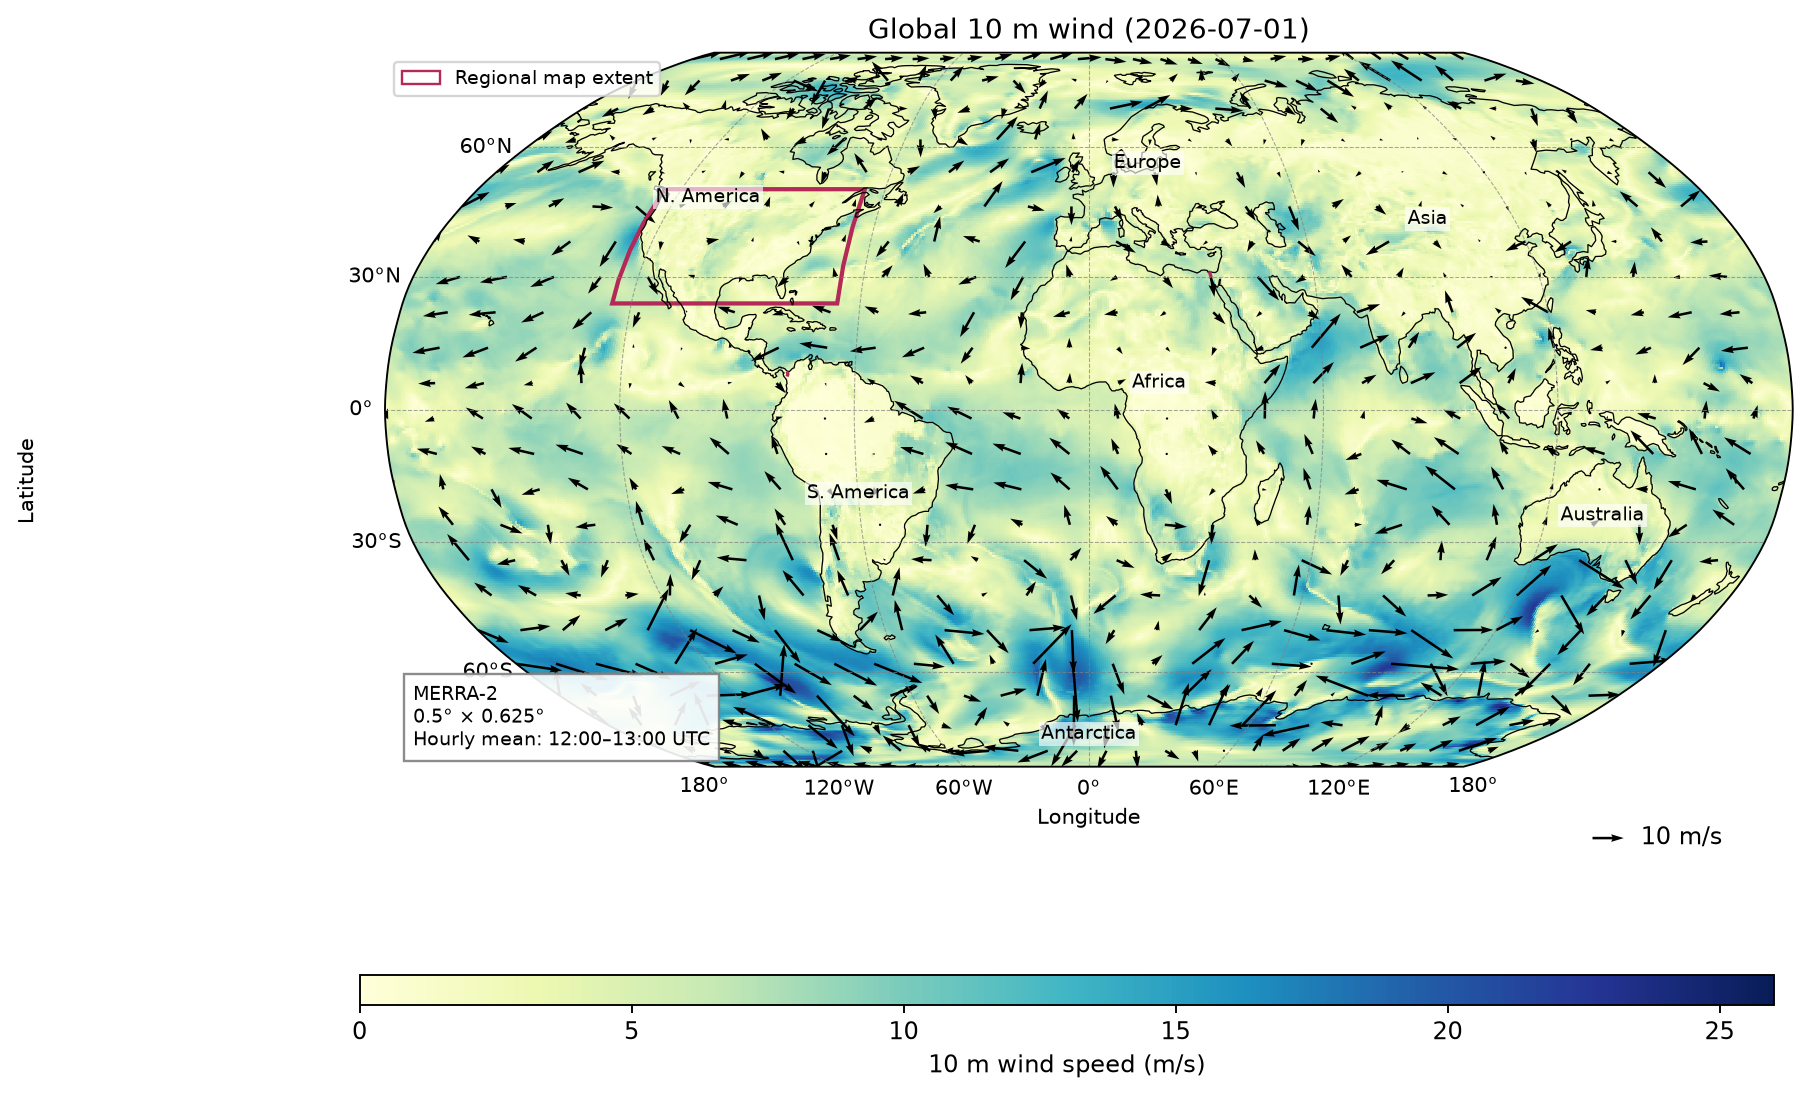

In [4]:
# 绘制全球风速、风向及洲际分界
fig = plt.figure(figsize=(13, 7))
ax = fig.add_axes([0.08, 0.32, 0.86, 0.60], projection=ccrs.Robinson())
ax.set_global()
values, lon = add_cyclic_point(speed.values, coord=wind.lon.values)
image = ax.pcolormesh(lon, wind.lat, values, cmap="YlGnBu", vmin=0, vmax=vmax,
                      transform=ccrs.PlateCarree())
arrows = ax.quiver(wind.lon.values[::20], wind.lat.values[::16], u.values[::16, ::20], v.values[::16, ::20],
                   transform=ccrs.PlateCarree(), scale=450, width=0.0018)
for line in divides["features"]:
    if line["properties"]["name"] == "Europe–Asia":
        continue
    points = np.array(line["geometry"]["coordinates"])
    ax.plot(points[:, 0], points[:, 1], "--", color="#b32957", lw=1.4, transform=ccrs.PlateCarree())
for name, x, y in [("N. America", -110, 47), ("S. America", -60, -20), ("Europe", 18, 55),
                    ("Africa", 18, 5), ("Asia", 95, 42), ("Australia", 135, -25), ("Antarctica", 0, -78)]:
    ax.text(x, y, name, transform=ccrs.PlateCarree(), fontsize=8, ha="center",
            bbox=dict(facecolor="white", alpha=0.65, edgecolor="none", pad=1))
ax.add_patch(Rectangle((-125, 24), 59, 26, facecolor="none", edgecolor="#b32957",
                       lw=1.8, transform=ccrs.PlateCarree()))
ax.legend(handles=[Rectangle((0, 0), 1, 1, fill=False, edgecolor="#b32957", label="Regional map extent")],
          loc="upper left", fontsize=8)
finish_map(fig, ax, image, arrows, "Global 10 m wind (2026-07-01)")

### 2.2

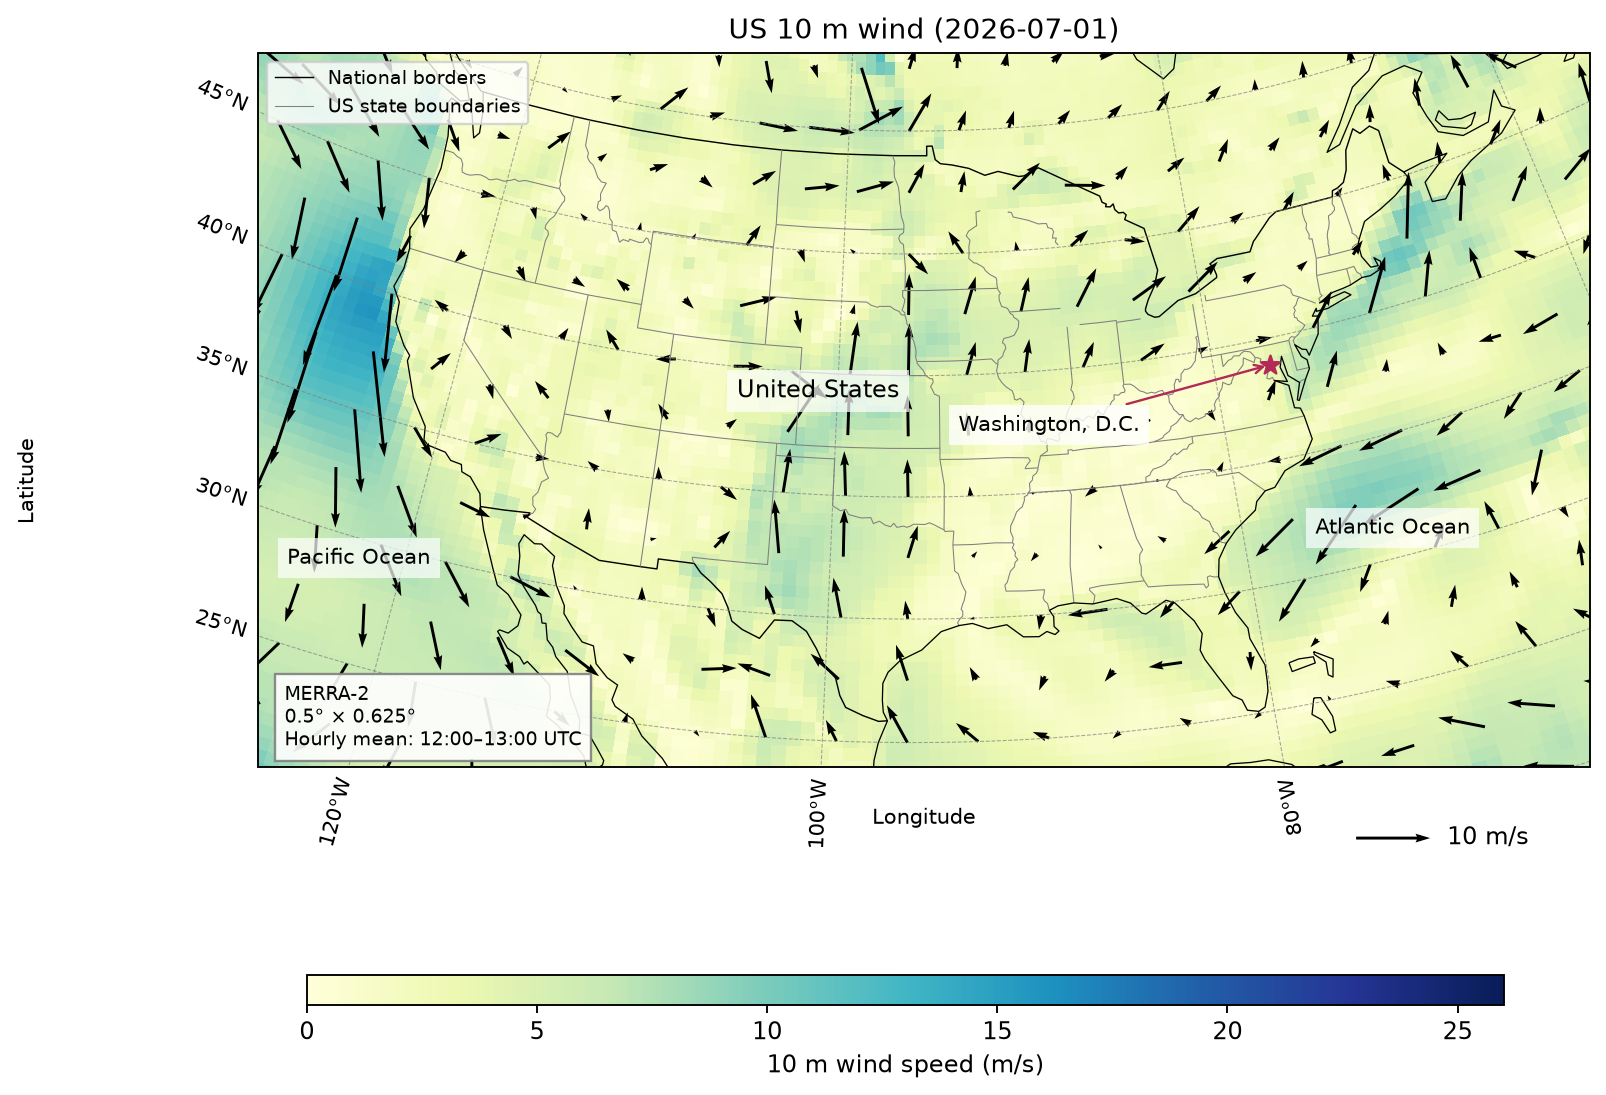

In [5]:
# 绘制美国本土风场和州界
us = wind.sel(lon=slice(-140, -50), lat=slice(10, 65))
fig = plt.figure(figsize=(11, 7))
ax = fig.add_axes([0.08, 0.32, 0.86, 0.60], projection=ccrs.LambertConformal(central_longitude=-96,
                      central_latitude=38, standard_parallels=(33, 45)))
ax.set_extent([-125, -66, 24, 50], crs=ccrs.PlateCarree())
image = ax.pcolormesh(us.lon, us.lat, np.hypot(us.U10M, us.V10M), cmap="YlGnBu",
                      vmin=0, vmax=vmax, transform=ccrs.PlateCarree())
arrows = ax.quiver(us.lon.values[::5], us.lat.values[::5], us.U10M.values[::5, ::5], us.V10M.values[::5, ::5],
                   transform=ccrs.PlateCarree(), scale=180, width=0.0022)
ax.add_geometries(borders, ccrs.PlateCarree(), facecolor="none", edgecolor="black", linewidth=0.6)
ax.add_geometries(states, ccrs.PlateCarree(), facecolor="none", edgecolor="gray", linewidth=0.45)
ax.text(-122, 29, "Pacific Ocean", transform=ccrs.PlateCarree(), fontsize=9,
        ha="center", bbox=dict(facecolor="white", alpha=0.7, edgecolor="none"))
ax.text(-73, 31, "Atlantic Ocean", transform=ccrs.PlateCarree(), fontsize=9,
        ha="center", bbox=dict(facecolor="white", alpha=0.7, edgecolor="none"))
ax.text(-101, 39, "United States", transform=ccrs.PlateCarree(), fontsize=10,
        ha="center", bbox=dict(facecolor="white", alpha=0.7, edgecolor="none"))
ax.scatter(-77.0369, 38.9072, marker="*", s=70, color="#b32957",
           transform=ccrs.PlateCarree(), zorder=5)
ax.annotate("Washington, D.C.", xy=(-77.0369, 38.9072),
            xycoords=ccrs.PlateCarree()._as_mpl_transform(ax),
            xytext=(-55, -28), textcoords="offset points", fontsize=9, ha="right",
            bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"),
            arrowprops=dict(arrowstyle="->", color="#b32957"))
ax.legend(handles=[Line2D([0], [0], color="black", lw=0.6, label="National borders"),
                   Line2D([0], [0], color="gray", lw=0.45, label="US state boundaries")],
          loc="upper left", fontsize=8)
finish_map(fig, ax, image, arrows, "US 10 m wind (2026-07-01)")